# 05 - Baseline

**Objetivo:** medir o erro da previsão mais simples possível, "a semana que vem vai ter os mesmos casos desta". Esse é o número que qualquer modelo da etapa 7 precisa bater, no mesmo período e com a mesma métrica.

Na EDA, os casos de uma semana tiveram correlação de 0,956 com os da semana anterior, então essa régua deve ser difícil de superar.

Leio `data/processed/dengue_clima_semanal.csv`, a tabela da etapa 4.

## 1. A previsão ingênua

A previsão de cada semana é o `casos_est` da semana anterior (`shift(1)`). Ela não aprende nada: só repete a última semana conhecida. Antes do `shift`, confiro que a tabela está em ordem e sem semana pulada.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dengue = pd.read_csv("../data/processed/dengue_clima_semanal.csv", parse_dates=["data_iniSE"])
dengue["ano"] = dengue["SE"] // 100

# O shift só vale se a tabela estiver em ordem e sem semana pulada (mesma checagem da EDA)
print("Em ordem:", dengue["data_iniSE"].is_monotonic_increasing)
print("Sempre 7 dias entre semanas:", (dengue["data_iniSE"].diff().dropna() == pd.Timedelta(days=7)).all())

# Baseline ingênuo: a previsão da semana t é o casos_est da semana t-1 (lag 1)
# Não aprende nada: só repete a última semana conhecida
dengue["previsao_ingenua"] = dengue["casos_est"].shift(1)
dengue[["data_iniSE", "casos_est", "previsao_ingenua"]].head(4)

Em ordem: True
Sempre 7 dias entre semanas: True


,data_iniSE,casos_est,previsao_ingenua
0,2015-01-04,50.0,NaN
1,2015-01-11,34.0,50.0
2,2015-01-18,51.0,34.0
3,2015-01-25,46.0,51.0


## 2. As regras da avaliação

Estas regras valem pra todos os modelos daqui pra frente:

- **Janela móvel anual.** Cada ano de 2019 a 2026 é um teste, e o treino é tudo o que veio antes dele. Assim o surto de 2022 vira um ano de teste, e os anos seguintes treinam já tendo visto ele. Um corte único deixaria 2022 sempre no treino e o teste sem nenhum surto daquele tamanho. O baseline não treina, mas é avaliado nos mesmos anos.
- **Só semanas fechadas.** As 20 semanas abertas ficam fora, porque o número delas ainda vai mudar. Por isso 2026 vai só até 24/05.
- **MAE e RMSE, na escala real de casos.** O MAE é o erro típico, em casos por semana. O RMSE eleva o erro ao quadrado, então mostra quem aguenta os picos. Nada de "acurácia", porque isso é regressão.

A função de erro é testada com um caso feito na mão antes de ser usada.

**Limitação:** no uso real, quando eu prevejo uma semana, o número da semana anterior ainda é provisório (o atraso de notificação). Aqui uso o valor já revisado, que não existia na hora. Isso deixa o baseline e os modelos um pouco otimistas, igual pros dois, e não dá pra corrigir sem as versões antigas de cada semana.

In [2]:
# Regras da avaliação (as mesmas pra todos os modelos da etapa 7)
# Janela móvel anual: cada ano de 2019 a 2026 é um teste; o treino seria tudo antes dele
# O baseline não treina, mas o período avaliado tem que ser o mesmo dos modelos
ANOS_TESTE = list(range(2019, 2027))


def calcular_erros(real, previsto):
    erro = real - previsto
    # MAE: média do tamanho do erro, em casos por semana (AVG(ABS(erro)) no SQL)
    mae = erro.abs().mean()
    # RMSE: eleva o erro ao quadrado antes da média, então erro grande pesa muito mais
    rmse = np.sqrt((erro ** 2).mean())
    return {"MAE": mae, "RMSE": rmse}


# Teste rápido da função com números feitos na mão: erros de 10, -10 e 40
# MAE = (10 + 10 + 40) / 3 = 20 | RMSE = raiz((100 + 100 + 1600) / 3) = raiz(600) = 24,49
calcular_erros(pd.Series([110, 90, 140]), pd.Series([100, 100, 100]))

{'MAE': np.float64(20.0), 'RMSE': np.float64(24.49489742783178)}

## 3. O erro ano a ano

Avalio o baseline em cada ano de teste e depois no total (as 387 semanas juntas), com e sem 2022. A coluna `MAE_pct_da_media` mostra o erro em % da média de casos do ano, pra dar pra comparar um ano calmo com um ano de surto.

In [3]:
# Avalia o baseline ano a ano, só nas semanas fechadas (as abertas ainda vão mudar)
resultados = []
semanas_avaliadas = []

for ano in ANOS_TESTE:
    teste = dengue[(dengue["ano"] == ano) & (~dengue["semana_aberta"])]
    erros = calcular_erros(teste["casos_est"], teste["previsao_ingenua"])

    resultados.append({
        "ano": ano,
        "semanas": len(teste),
        "media_casos": teste["casos_est"].mean(),
        "MAE": erros["MAE"],
        "RMSE": erros["RMSE"],
        # MAE em % da média de casos do ano: deixa comparar ano calmo com ano de surto
        "MAE_pct_da_media": erros["MAE"] / teste["casos_est"].mean() * 100,
    })
    semanas_avaliadas.append(teste)

resultados_baseline = pd.DataFrame(resultados)
resultados_baseline.round(1)

,ano,semanas,media_casos,MAE,RMSE,MAE_pct_da_media
0,2019,52,105.0,18.7,28.2,17.8
1,2020,53,23.5,7.8,11.1,33.0
2,2021,52,23.4,7.9,12.7,33.6
3,2022,52,311.0,83.9,147.4,27.0
4,2023,52,106.4,16.3,23.0,15.3
5,2024,52,152.0,30.4,40.7,20.0
6,2025,53,116.9,15.0,22.2,12.8
7,2026,21,315.8,43.8,62.0,13.9


In [4]:
# Total: junta as semanas de todos os anos de teste e calcula o erro de uma vez
todas_avaliadas = pd.concat(semanas_avaliadas)
total = calcular_erros(todas_avaliadas["casos_est"], todas_avaliadas["previsao_ingenua"])
print("Semanas avaliadas:", len(todas_avaliadas))
print("Total      -> MAE:", round(total["MAE"], 1), "| RMSE:", round(total["RMSE"], 1))

# O mesmo sem 2022, pra ver o quanto um ano de surto mexe no número final
sem_2022 = todas_avaliadas[todas_avaliadas["ano"] != 2022]
total_sem_2022 = calcular_erros(sem_2022["casos_est"], sem_2022["previsao_ingenua"])
print("Sem 2022   -> MAE:", round(total_sem_2022["MAE"], 1), "| RMSE:", round(total_sem_2022["RMSE"], 1))

Semanas avaliadas: 387
Total      -> MAE: 26.6 | RMSE: 60.3
Sem 2022   -> MAE: 17.7 | RMSE: 28.7


### Conclusões do erro ano a ano

- No total, o baseline erra em média **26,6 casos por semana** (RMSE 60,3). Esse é o número a bater.
- 2022 é o ano mais difícil: MAE 83,9 e RMSE 147,4. Sem ele, o total cai pra MAE 17,7 e RMSE 28,7, ou seja, um ano de surto dobra o RMSE.
- Em casos, 2020 e 2021 têm o menor erro (cerca de 8 por semana), mas ele é um terço da média de casos desses anos. Em 2025, o erro é 15 casos e só 13% da média.

## 4. Pra que lado o baseline erra

O erro é `real − previsto`: positivo quando o baseline previu de menos, negativo quando previu de mais.

In [5]:
# Pra que lado o baseline erra? erro = real - previsto
# erro > 0: previu de menos (os casos subiram); erro < 0: previu de mais (os casos caíram)
todas_avaliadas = todas_avaliadas.copy()
todas_avaliadas["erro"] = todas_avaliadas["casos_est"] - todas_avaliadas["previsao_ingenua"]
todas_avaliadas["momento"] = np.where(todas_avaliadas["erro"] > 0, "subindo", "caindo ou parado")

todas_avaliadas.groupby("momento")["erro"].agg(["count", "mean"]).round(1)

,count,mean
momento,,
caindo ou parado,194,-24.4
subindo,193,28.8


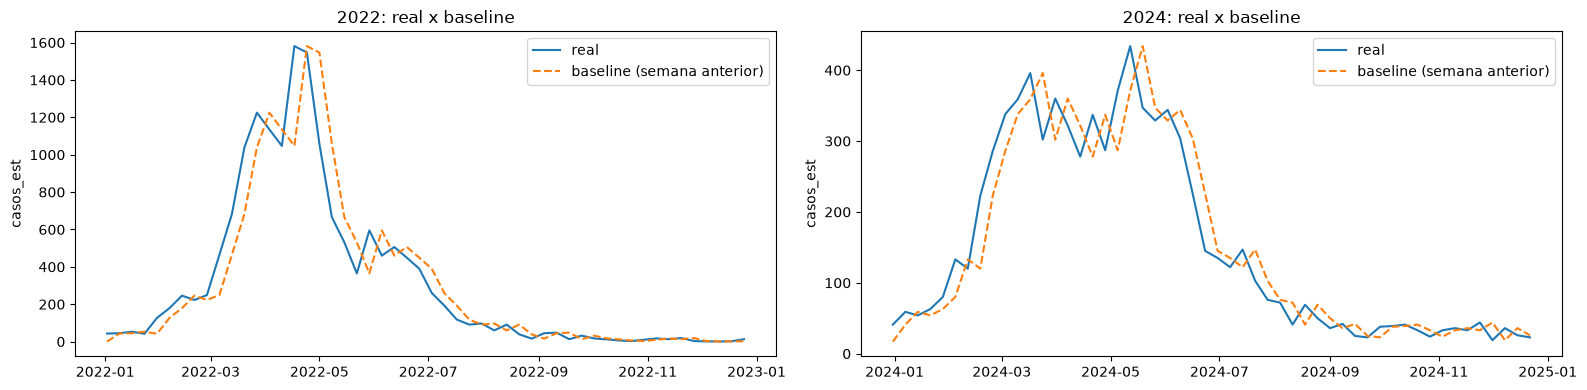

In [6]:
# Real x baseline em 2022 (o surto) e 2024 (um ano normal): a previsão é a curva real atrasada uma semana
fig, eixos = plt.subplots(1, 2, figsize=(16, 4))

for eixo, ano in zip(eixos, [2022, 2024]):
    do_ano = todas_avaliadas[todas_avaliadas["ano"] == ano]
    eixo.plot(do_ano["data_iniSE"], do_ano["casos_est"], label="real")
    eixo.plot(do_ano["data_iniSE"], do_ano["previsao_ingenua"], linestyle="--", label="baseline (semana anterior)")
    eixo.set_title(f"{ano}: real x baseline")
    eixo.set_ylabel("casos_est")
    eixo.legend()

plt.tight_layout()
plt.show()

### Conclusões

- O baseline está sempre uma semana atrasado: quando os casos sobem, ele prevê de menos (erro médio de +28,8); quando caem, prevê de mais (−24,4). No gráfico, a linha tracejada é a curva real empurrada uma semana pra direita.
- O maior erro foi no pico de 2022: na semana de 17/04, o real foi 1.581 e o baseline previu 1.047, o valor da semana anterior.
- A régua pra etapa 7 é **MAE 26,6 e RMSE 60,3** nos anos de teste de 2019 a 2026, olhando também cada ano, principalmente 2022. Um modelo só vale a pena se errar menos que isso nas mesmas semanas. O lugar onde dá pra ganhar é antecipar as viradas, a subida e a queda.